# Introduction

This notebook demonstrates how to use CNit with parameters calibrated to emulate 16 CMIP6 Earth system models (ESMs).

The calibrated parameters, forcing data, and calibration targets are available from [CNit Model Calibration and Results](https://doi.org/10.5281/zenodo.18116573). Before running the notebook, place the following three data files in the project-level `data/` directory:

- **Calibrated parameters:** `cali_cmip6_best_fitting.csv`
- **Forcing data:** `CMIP6_cali_forcing.nc` (CO₂, climate, land-use, and nitrogen-related inputs for a range of experiments)
- **Calibration targets:** `CMIP6_cali_target.nc` (ESM outputs for a range of experiments)

This example notebook `CNit_example_CMIP6_ESMs_emulation.ipynb` is in the project-level `notebooks/` directory.

We use 1pctCO2, hist_ssp245, and hist_ssp585 as examples. Briefly:

- **1pctCO2**: Atmospheric CO₂ increases by 1% per year, while other forcings remain at pre-industrial levels.
- **hist_ssp245**: Historical forcings for 1850–2014 are followed by the SSP2-4.5 scenario for 2015–2100. 
- **hist_ssp585**: Historical forcings for 1850–2014 are followed by the SSP5-8.5 scenario for 2015–2100. 

For details on the CMIP6 experiments, see the [CMIP6 experimental design overview](https://doi.org/10.5194/gmd-9-1937-2016) and the [CMIP6 ScenarioMIP overview](https://doi.org/10.5194/gmd-9-3461-2016).

# Import required libraries and modules

In [1]:
%load_ext nb_black
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from pathlib import Path

<IPython.core.display.Javascript object>

In [2]:
from cnit import CNitModel, CNitModelConfig, CNitExpConfig
from cnit import Q  # Local pint.quantity class for units handling

<IPython.core.display.Javascript object>

# Set default plotting properties

In [3]:
plt.rcParams.update(
    {
        "font.size": 6,  # Default font size for all text
        "axes.titlesize": 6,  # Axes title
        "axes.labelsize": 6,  # Axes labels
        "xtick.labelsize": 6,  # X-axis tick labels
        "ytick.labelsize": 6,  # Y-axis tick labels
        "legend.fontsize": 6,  # Legend text
        "figure.titlesize": 6,  # Figure title
        "lines.linewidth": 0.5,  # Default line width
        "figure.figsize": (9 / 2.54, 6 / 2.54),  # Default figure size in cm
        "figure.dpi": 150,  # Default DPI for figures
        "figure.constrained_layout.use": True,  # Use constrained layout by default
        "xtick.major.size": 1,  # X-axis major tick length
        "ytick.major.size": 1,  # Y-axis major tick length
    }
)

<IPython.core.display.Javascript object>

# Read forcing data and ESM outputs

Place the CMIP6 forcing, target, and calibration CSV files in the project-level
data/ directory. The path setup below also works when the notebook is run from
the notebooks/ directory.

In [4]:
# Locate the repository-level data directory when running from the project root
# or from notebooks/.
project_root = Path.cwd()
if not (project_root / "data").is_dir():
    project_root = project_root.parent
data_path = project_root / "data"
parameter_csv = data_path / "cali_cmip6_best_fitting.csv"

<IPython.core.display.Javascript object>

In [5]:
forcing_data = xr.open_dataset(data_path / "CMIP6_cali_forcing.nc")
target_data = xr.open_dataset(data_path / "CMIP6_cali_target.nc")

<IPython.core.display.Javascript object>

In [6]:
# add hist_sspXXX to the forcing data and the target data
ssp_scenarios = [
    "ssp119",
    "ssp126",
    "ssp245",
    "ssp370",
    "ssp460",
    "ssp585",
]

for name in ["forcing_data", "target_data"]:
    ds = globals()[name]
    historical = ds.sel(experiment="historical", drop=True)

    combined_list = []
    for ssp in ssp_scenarios:
        ssp_data = ds.sel(experiment=ssp, drop=True)
        combined = xr.where(ds.time <= 2014, historical, ssp_data)
        combined_list.append(combined.expand_dims(experiment=[f"hist_{ssp}"]))

    ds = xr.concat([ds, *combined_list], dim="experiment", join="outer")

    if name == "forcing_data":
        forcing_data = ds
    else:
        target_data = ds

<IPython.core.display.Javascript object>

In [7]:
# map ESM outputs to corresponding CNit variables

target_data["CflxNPP"] = target_data["npp"]
target_data["CplsPLS"] = (
    target_data["cVeg"] + target_data["cLitter"].fillna(0) + target_data["cSoil"]
)
target_data["CflxNetPLS"] = target_data["CplsPLS"].differentiate("time")

target_data["NflxBNF"] = target_data["fBNF"]
target_data["NplsPLS"] = (
    target_data["nVeg"] + target_data["nLitter"].fillna(0) + target_data["nSoil"]
)
target_data["NplsM"] = target_data["nMineral"]
target_data["NflxNetPLSM"] = (
    target_data["NplsPLS"] + target_data["nMineral"].fillna(0)
).differentiate("time")

<IPython.core.display.Javascript object>

# Read calibrated parameters

Each source model has a column in the CSV. The corresponding CNit configuration
is loaded from that selected column with from_parameter_csv.

In [8]:
cali_para_df = pd.read_csv(parameter_csv, index_col=0)

<IPython.core.display.Javascript object>

In [9]:
mdl_list = [name for name in cali_para_df.columns if name != "unit"]
print(mdl_list)

['ACCESS-ESM1-5', 'CMCC-CM2-SR5', 'CMCC-ESM2', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'NorESM2-LM', 'NorESM2-MM', 'UKESM1-0-LL', 'CESM2-WACCM', 'TaiESM1', 'BCC-CSM2-MR', 'CNRM-ESM2-1', 'CanESM5', 'CanESM5-1', 'IPSL-CM6A-LR', 'EC-Earth3-Veg']


<IPython.core.display.Javascript object>

# Configure models and experiments

Each model configuration is loaded from its calibration CSV column. CNitExpConfig
stores the forcing for each experiment.

In [10]:
mdl_cfg_by_mdl = {}

for mdl in mdl_list:
    mdl_cfg = CNitModelConfig.from_parameter_csv(
        parameter_csv,
        model_name=mdl,
    )
    mdl_cfg_by_mdl[mdl] = mdl_cfg

<IPython.core.display.Javascript object>

In [11]:
exp_cfgs_by_mdl = {}

for mdl in mdl_list:
    exp_cfgs_by_mdl[mdl] = []

    for exp in ["1pctCO2", "hist_ssp245", "hist_ssp585"]:
        exp_forcing = forcing_data.sel(model=mdl, experiment=exp)

        valid_time = exp_forcing["CO2"].dropna(dim="time").time.data
        exp_forcing = exp_forcing.sel(time=valid_time)

        switch_N = Q(0, "1") if "Conly" in exp else mdl_cfg_by_mdl[mdl].switch_N
        exp_cfg = CNitExpConfig(
            name=exp,
            switch_N=switch_N,
            time_axis=Q(exp_forcing["time"].data, "yr"),
            dT_s=Q(exp_forcing["dT"].data, exp_forcing["dT"].unit),
            CO2_s=Q(exp_forcing["CO2"].data, exp_forcing["CO2"].unit),
            CemsLUnet_s=Q(exp_forcing["CemsLUnet"].data, exp_forcing["CemsLUnet"].unit),
            CemsLUgrs_s=Q(exp_forcing["CemsLUgrs"].data, exp_forcing["CemsLUgrs"].unit),
            NflxAD_s=Q(exp_forcing["NflxAD"].data, exp_forcing["NflxAD"].unit),
            NflxFT_s=Q(exp_forcing["NflxFT"].data, exp_forcing["NflxFT"].unit),
            NemsLUnet_s=Q(exp_forcing["NemsLUnet"].data, exp_forcing["NemsLUnet"].unit),
            NemsLUgrs_s=Q(exp_forcing["NemsLUgrs"].data, exp_forcing["NemsLUgrs"].unit),
            NemsLUmin_s=Q(exp_forcing["NemsLUmin"].data, exp_forcing["NemsLUmin"].unit),
        )

        exp_cfgs_by_mdl[mdl].append(exp_cfg)

<IPython.core.display.Javascript object>

# Run experiments with emulated ESMs

Here we run the 1pctCO2, hist_ssp245, hist_ssp585 experiments with the ESM-calibrated CNit. 

In [12]:
%%time

res = []

for mdl in mdl_list:
    mdl_cfg = mdl_cfg_by_mdl[mdl]
    exp_cfgs = exp_cfgs_by_mdl[mdl]

    cnit_mdl = CNitModel.from_config(mdl_cfg)
    mdl_res = cnit_mdl.run_experiments(exp_cfgs)
    mdl_res = mdl_res.assign_coords(model=mdl).expand_dims("model")
    res.append(mdl_res)
    print("finished:", mdl)

res_ds = xr.concat(res, dim="model")

finished: ACCESS-ESM1-5
finished: CMCC-CM2-SR5
finished: CMCC-ESM2
finished: MIROC-ES2L
finished: MPI-ESM1-2-LR
finished: NorESM2-LM
finished: NorESM2-MM
finished: UKESM1-0-LL
finished: CESM2-WACCM
finished: TaiESM1
finished: BCC-CSM2-MR
finished: CNRM-ESM2-1
finished: CanESM5
finished: CanESM5-1
finished: IPSL-CM6A-LR
finished: EC-Earth3-Veg
CPU times: user 6.51 s, sys: 53.6 ms, total: 6.56 s
Wall time: 6.55 s


<IPython.core.display.Javascript object>

# Visualize results

The results below show the agreement between ESM outputs and CNit emulations, demonstrating the emulation performance of the calibrated CNit. 

In [13]:
def plot_single_model(axs, var, mdl):
    for ax, exp in zip(axs, ["1pctCO2", "hist_ssp245", "hist_ssp585"]):
        data_ = target_data[var].sel(model=mdl, experiment=exp).dropna(dim="time")
        time = data_.time.data

        mdl_ = res_ds[var].sel(model=mdl, experiment=exp, time=time)

        if np.nansum(data_) != 0:
            ax.plot(time, data_, linewidth=1)
            ax.plot(time, mdl_, "--", linewidth=1)
            ax.text(
                0.05,
                0.9,
                exp,
                transform=ax.transAxes,
                ha="left",
                va="center",
                fontsize=6,
            )

    for ax in axs:
        if len(ax.lines) != 0:
            ax.set_title(mdl)
            break

<IPython.core.display.Javascript object>

In [14]:
experiments = ["1pctCO2", "hist_ssp245", "hist_ssp585"]

n_model_per_row = 4  # number of models per row
n_models = len(mdl_list)
n_rows = int(np.ceil(n_models / n_model_per_row))
n_cols = n_model_per_row * len(experiments)

<IPython.core.display.Javascript object>

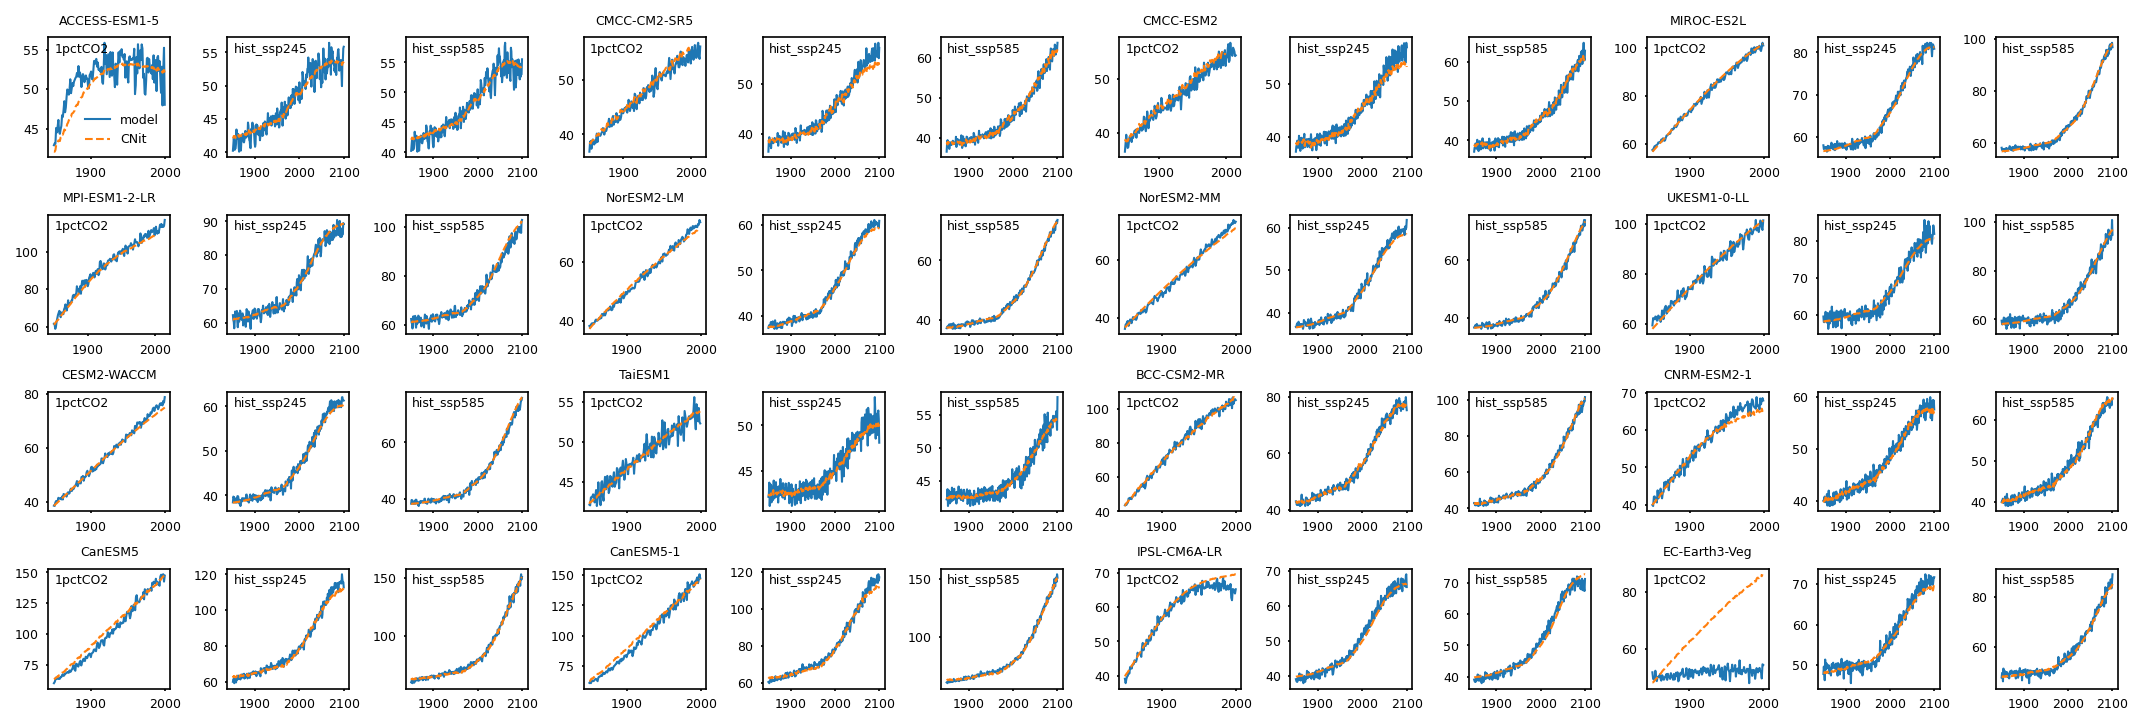

<IPython.core.display.Javascript object>

In [15]:
var = "CflxNPP"

fig, axs = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols / 2.54, 3 * n_rows / 2.54))
for idx, mdl in enumerate(mdl_list):
    row = idx // n_model_per_row
    col_start = (idx % n_model_per_row) * len(experiments)
    axs_row = axs[row, col_start : col_start + len(experiments)]
    plot_single_model(axs_row, var, mdl)

axs[0, 0].legend(["model", "CNit"], frameon=0, loc="lower right")

for ax in axs.flat:
    if len(ax.lines) == 0:
        ax.remove()

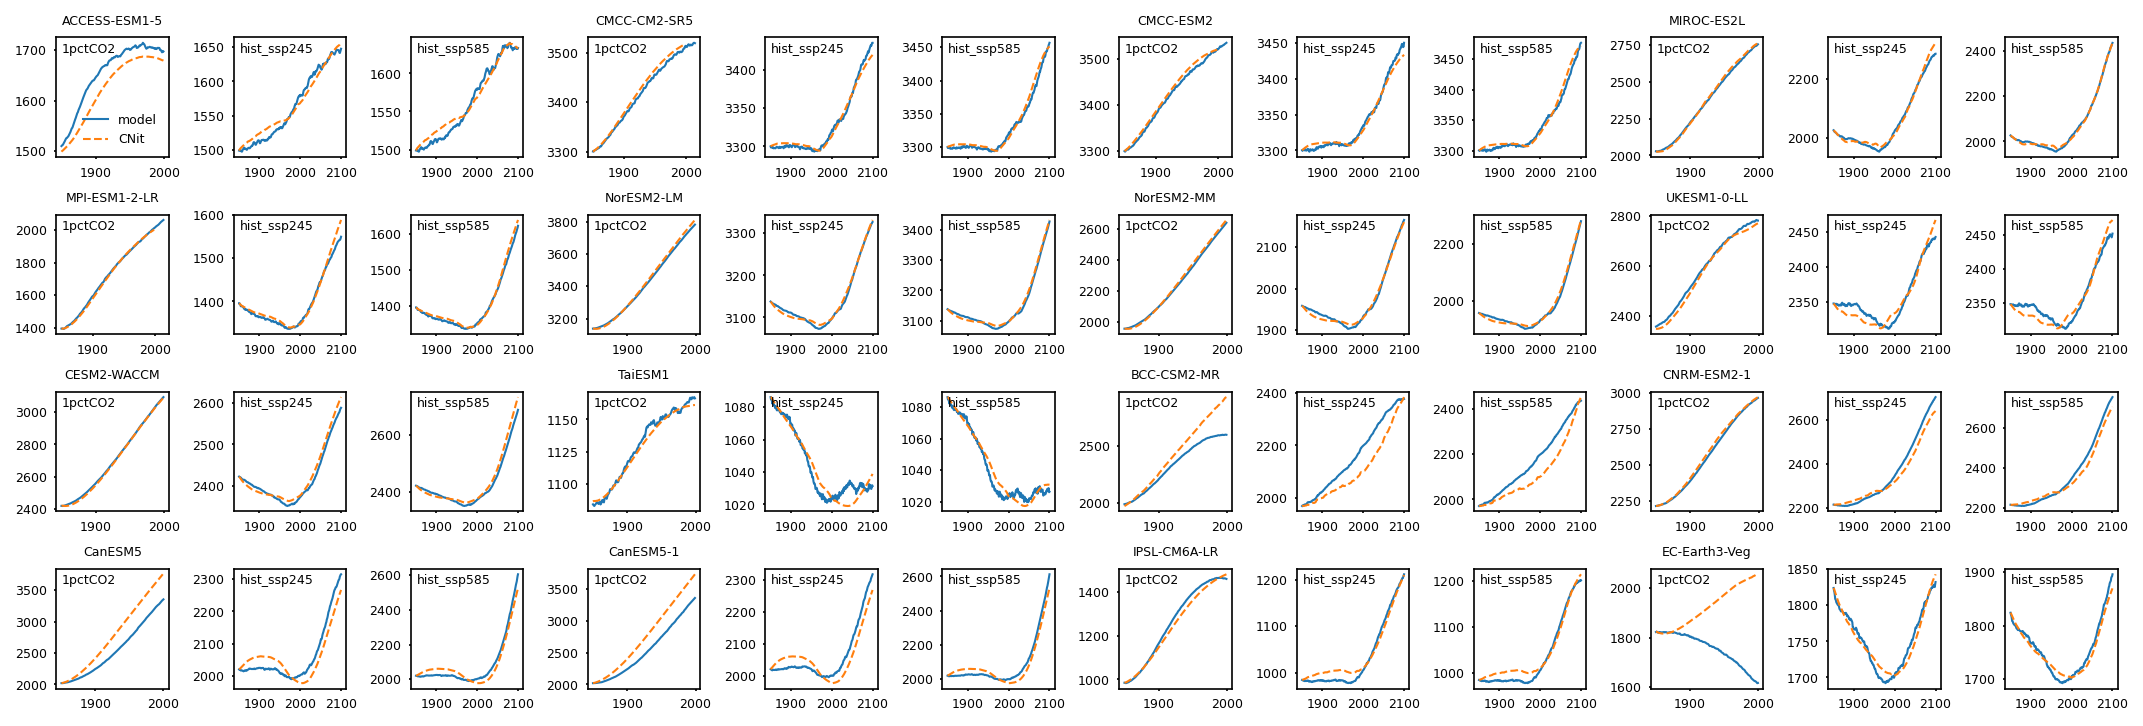

<IPython.core.display.Javascript object>

In [16]:
var = "CplsPLS"

fig, axs = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols / 2.54, 3 * n_rows / 2.54))
for idx, mdl in enumerate(mdl_list):
    row = idx // n_model_per_row
    col_start = (idx % n_model_per_row) * len(experiments)
    axs_row = axs[row, col_start : col_start + len(experiments)]
    plot_single_model(axs_row, var, mdl)

axs[0, 0].legend(["model", "CNit"], frameon=0, loc="lower right")

for ax in axs.flat:
    if len(ax.lines) == 0:
        ax.remove()

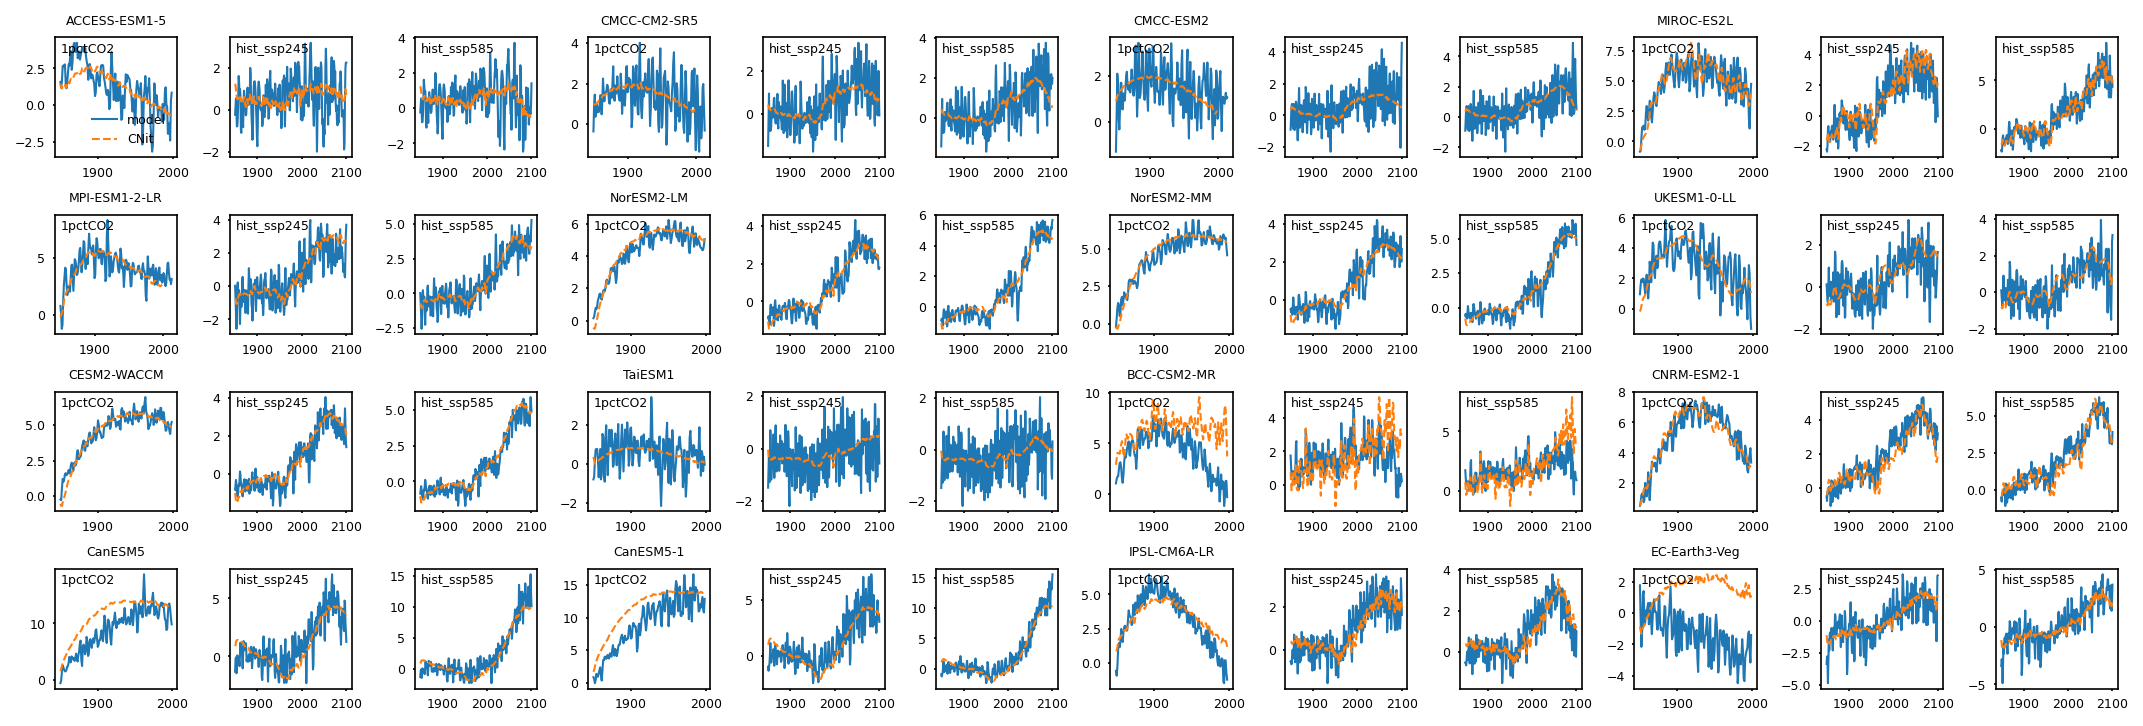

<IPython.core.display.Javascript object>

In [17]:
var = "CflxNetPLS"

fig, axs = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols / 2.54, 3 * n_rows / 2.54))
for idx, mdl in enumerate(mdl_list):
    row = idx // n_model_per_row
    col_start = (idx % n_model_per_row) * len(experiments)
    axs_row = axs[row, col_start : col_start + len(experiments)]
    plot_single_model(axs_row, var, mdl)

axs[0, 0].legend(["model", "CNit"], frameon=0, loc="lower right")

for ax in axs.flat:
    if len(ax.lines) == 0:
        ax.remove()

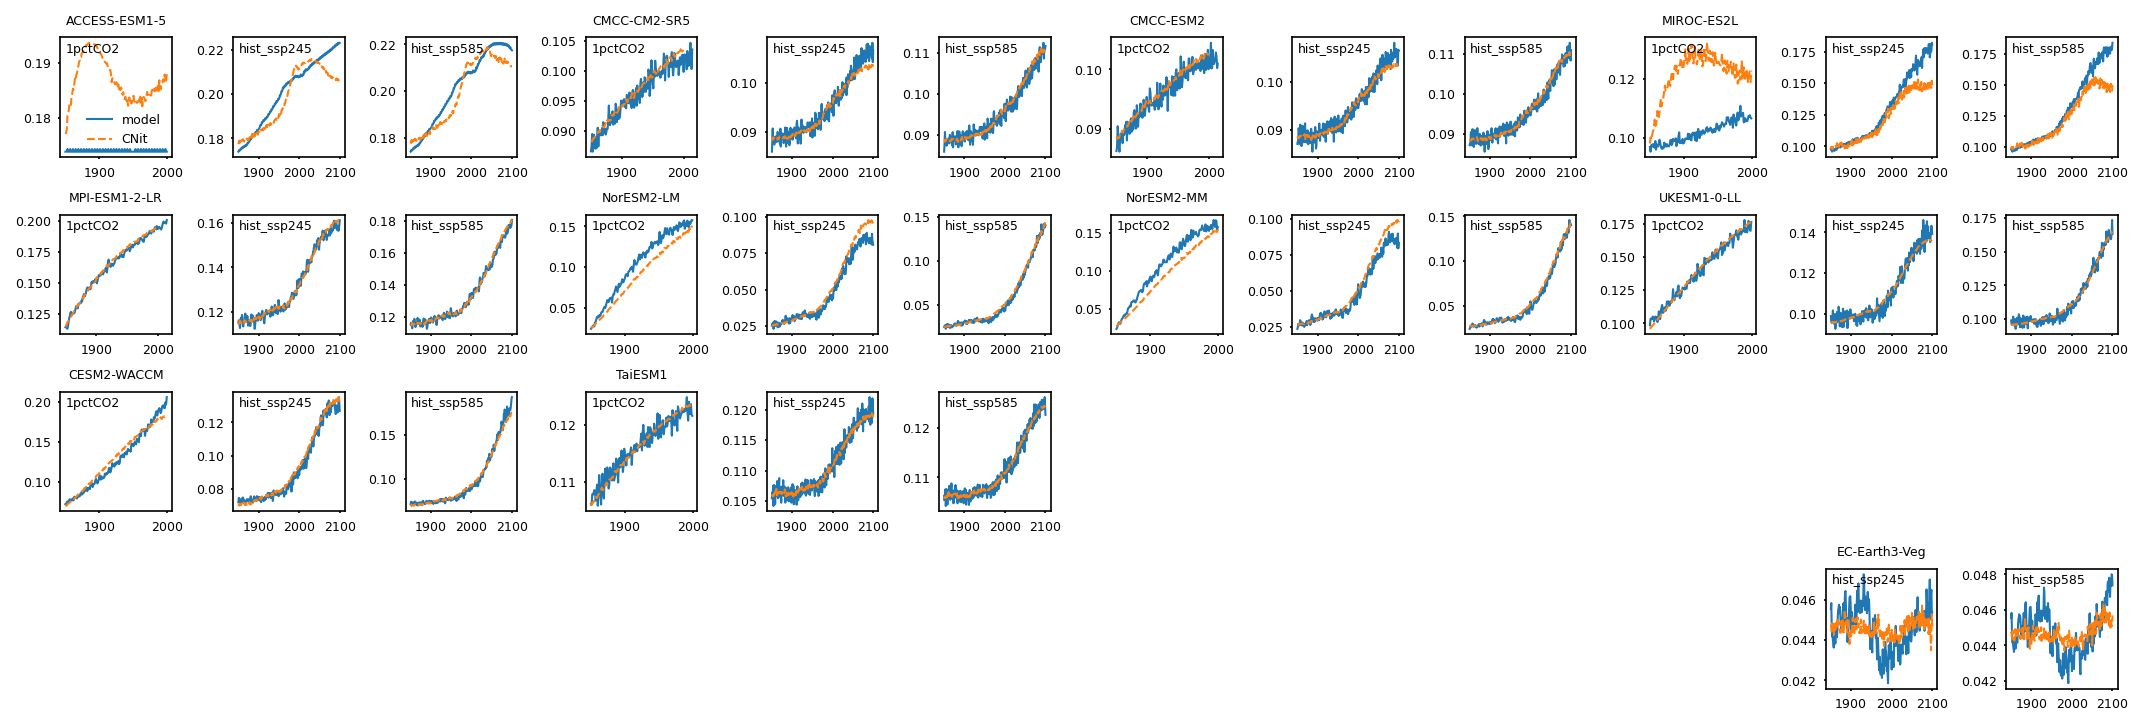

<IPython.core.display.Javascript object>

In [18]:
var = "NflxBNF"

fig, axs = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols / 2.54, 3 * n_rows / 2.54))
for idx, mdl in enumerate(mdl_list):
    row = idx // n_model_per_row
    col_start = (idx % n_model_per_row) * len(experiments)
    axs_row = axs[row, col_start : col_start + len(experiments)]
    plot_single_model(axs_row, var, mdl)

axs[0, 0].legend(["model", "CNit"], frameon=0, loc="lower right")

for ax in axs.flat:
    if len(ax.lines) == 0:
        ax.remove()

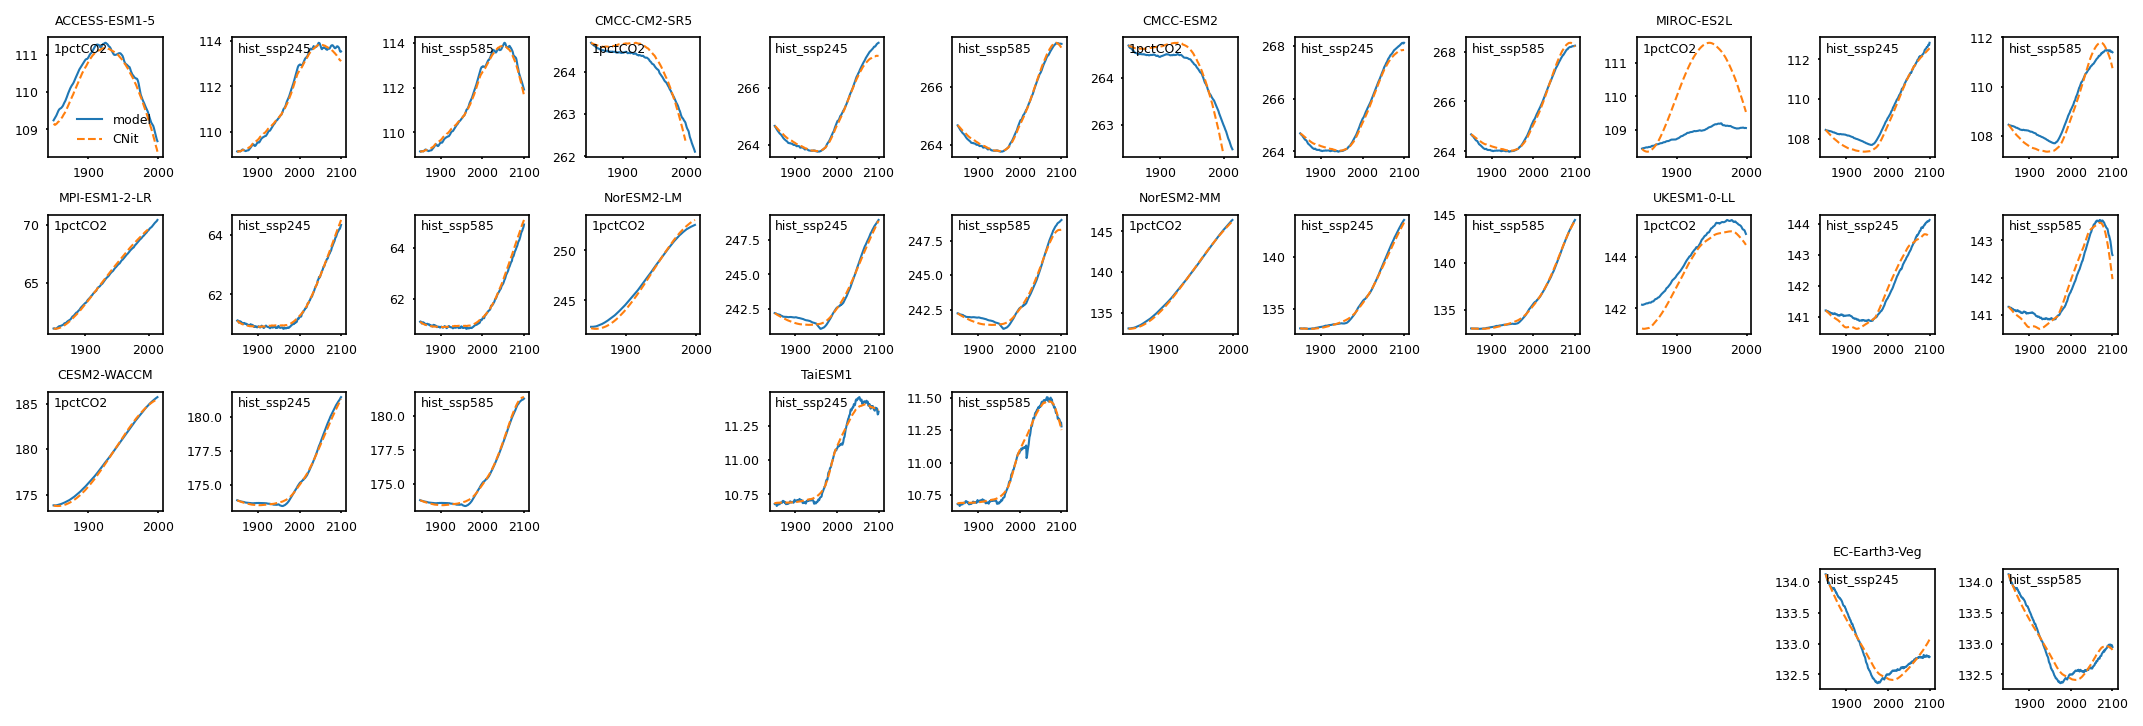

<IPython.core.display.Javascript object>

In [19]:
var = "NplsPLS"

fig, axs = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols / 2.54, 3 * n_rows / 2.54))
for idx, mdl in enumerate(mdl_list):
    row = idx // n_model_per_row
    col_start = (idx % n_model_per_row) * len(experiments)
    axs_row = axs[row, col_start : col_start + len(experiments)]
    plot_single_model(axs_row, var, mdl)

axs[0, 0].legend(["model", "CNit"], frameon=0, loc="lower right")

for ax in axs.flat:
    if len(ax.lines) == 0:
        ax.remove()

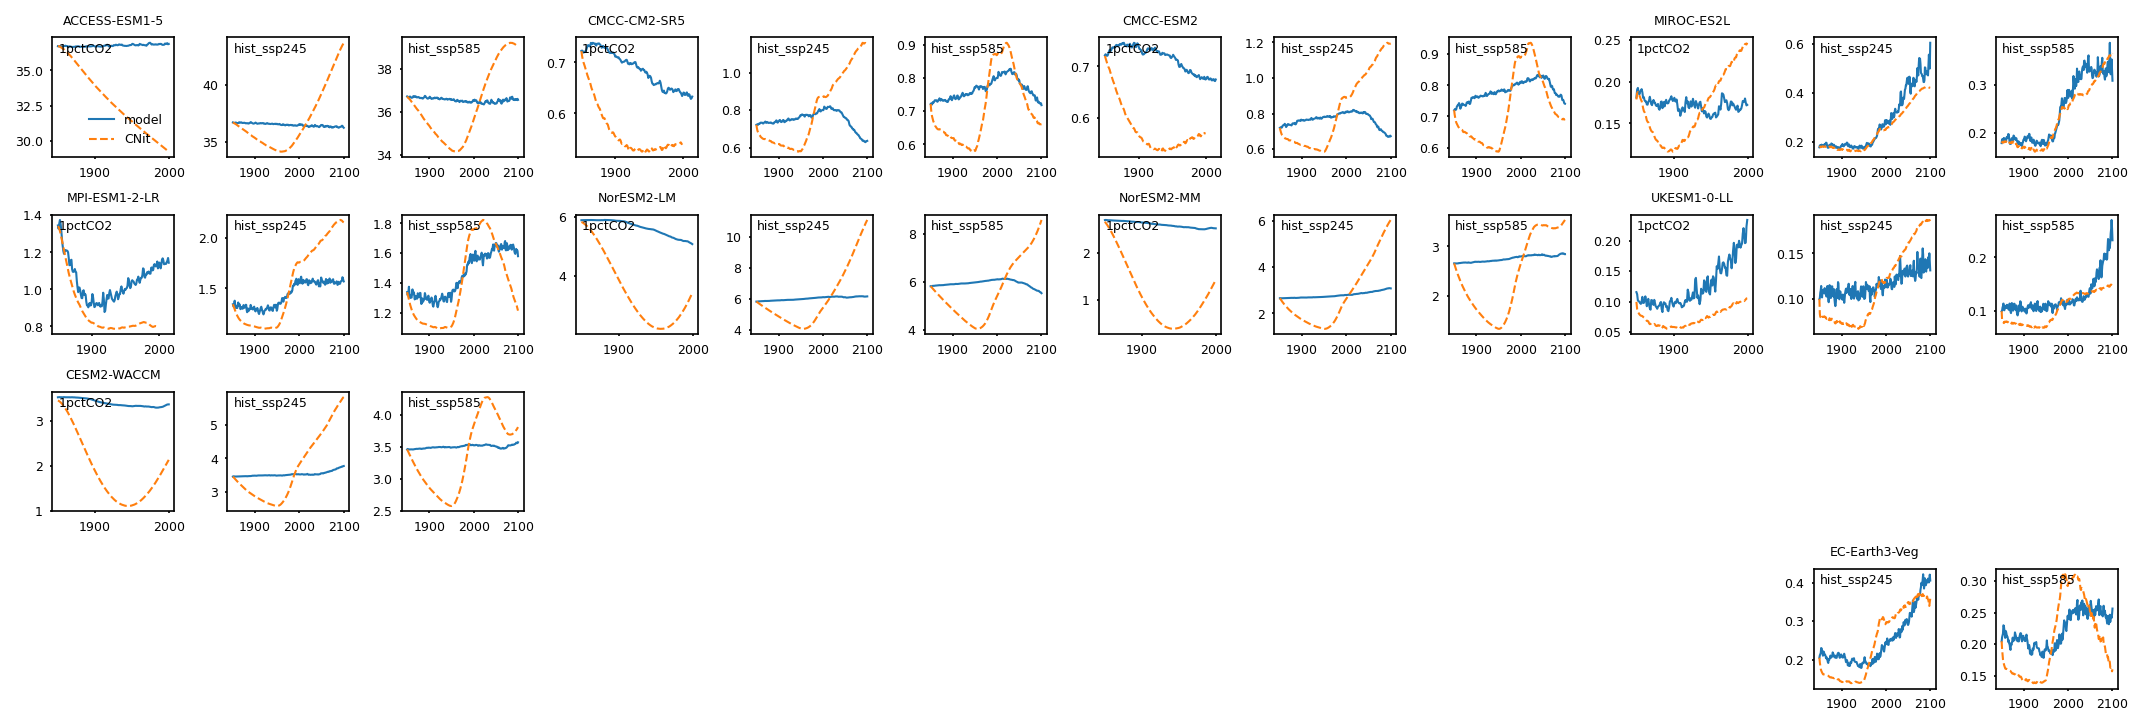

<IPython.core.display.Javascript object>

In [20]:
var = "NplsM"

fig, axs = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols / 2.54, 3 * n_rows / 2.54))
for idx, mdl in enumerate(mdl_list):
    row = idx // n_model_per_row
    col_start = (idx % n_model_per_row) * len(experiments)
    axs_row = axs[row, col_start : col_start + len(experiments)]
    plot_single_model(axs_row, var, mdl)

axs[0, 0].legend(["model", "CNit"], frameon=0, loc="lower right")

for ax in axs.flat:
    if len(ax.lines) == 0:
        ax.remove()

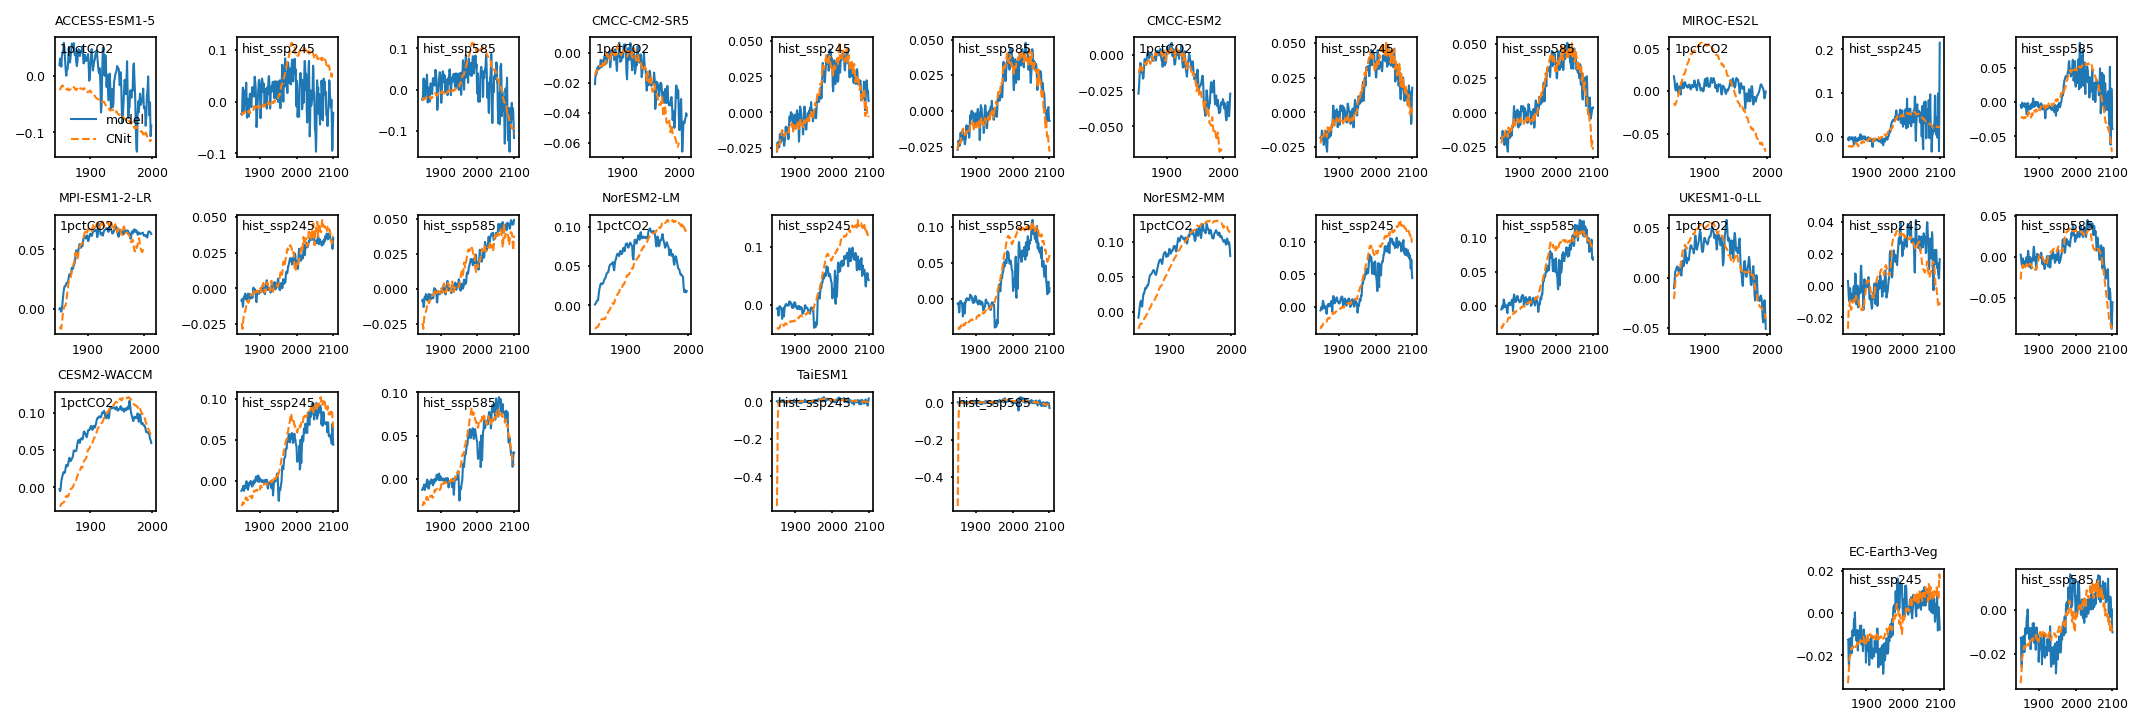

<IPython.core.display.Javascript object>

In [21]:
var = "NflxNetPLSM"

fig, axs = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols / 2.54, 3 * n_rows / 2.54))
for idx, mdl in enumerate(mdl_list):
    row = idx // n_model_per_row
    col_start = (idx % n_model_per_row) * len(experiments)
    axs_row = axs[row, col_start : col_start + len(experiments)]
    plot_single_model(axs_row, var, mdl)

axs[0, 0].legend(["model", "CNit"], frameon=0, loc="lower right")

for ax in axs.flat:
    if len(ax.lines) == 0:
        ax.remove()